# APRAU 2026/27: Grupo 18 — Análise complementar

**Autor:** Lourenço Mendes (n.º 1201270)

Este notebook complementa o notebook principal (`aprau_grupo18.ipynb`). Usa o mesmo dataset e o mesmo pré-processamento
(remoção de `calcium_baseline`, `systolic_index` e `age_normalized`; one-hot com `drop_first=True`) e responde a pontos
que o principal não cobre ou cobre de forma incompleta:

1. **EDA:** associação das features **categóricas** com os dois alvos; descoberta de **duas fontes de dados** (medidos vs imputados); multicolinearidade das categóricas com **GVIF**.
2. **Regressão:** testes de significância (OLS), análise de resíduos e alternativas testadas para descartar.
3. **Classificação:** variância **das estimativas** de cada método de reamostragem; métricas para classes desequilibradas; tratamento do desequilíbrio (pesos, priors, limiar).
4. **Seleção de features:** conjuntos alternativos de features.
5. Conclusões e implicações para o notebook principal.

## 0. Setup

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.preprocessing import StandardScaler, LabelEncoder, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeCV, LassoCV
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import (train_test_split, cross_val_score, cross_val_predict, cross_validate,
                                     StratifiedKFold, RepeatedKFold, RepeatedStratifiedKFold)
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score, roc_auc_score,
                             recall_score, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (10, 5)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
RANDOM_STATE = 42

# Mesma lógica do notebook principal: Google Drive no Colab, raiz do repo em execução local
import sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATASET_PATH = '/content/drive/MyDrive/APRAU/dataset_grupo_18.csv'
else:
    CANDIDATES = ['../dataset_grupo_18.csv', '../../T/dataset_grupo_18.csv', 'dataset_grupo_18.csv']
    DATASET_PATH = next(p for p in CANDIDATES if os.path.exists(p))
df = pd.read_csv(DATASET_PATH)
print('Dataset:', DATASET_PATH, df.shape)

Dataset: ../dataset_grupo_18.csv (2000, 35)


Mesmo pré-processamento do notebook principal (secções 2.6 e 2.8).

In [2]:
df_clean = df.drop(columns=['calcium_baseline', 'systolic_index', 'age_normalized'])
CAT_COLS = [c for c in df_clean.select_dtypes(exclude=[np.number]).columns if c != 'target_class']
NUM_COLS = [c for c in df_clean.select_dtypes(include=[np.number]).columns if c != 'target_regression']

df_enc = pd.get_dummies(df_clean, columns=CAT_COLS, drop_first=True, dtype=int)
df_enc['target_class'] = LabelEncoder().fit_transform(df_clean['target_class'])   # DI=0, HT=1, N=2
FEATURES = [c for c in df_enc.columns if c not in ['target_regression', 'target_class']]
X_all = df_enc[FEATURES].values
y_class = df_enc['target_class'].values
y_reg = df_enc['target_regression'].values
print(f'{len(FEATURES)} features | categóricas: {len(CAT_COLS)} | numéricas: {len(NUM_COLS)}')

40 features | categóricas: 12 | numéricas: 18


---
## 1. EDA complementar

### 1.1 Features categóricas vs `target_class`

O notebook principal faz a análise bivariada apenas com as features numéricas. Para as categóricas usamos o
**teste do qui-quadrado** de independência e o **V de Cramér** ($V = \sqrt{\chi^2 / (n \cdot (\min(r,c)-1))}$), que mede a força
da associação entre 0 (nenhuma) e 1 (total), independentemente do número de categorias.

,Feature,chi2,gl,p-value,V de Cramér
0,age_level,144.3,6,1.3e-28,0.190
1,smoking,98.2,4,2.4e-20,0.157
2,bmi_level,53.1,6,1.1e-09,0.115
3,gender,25.6,2,2.7e-06,0.113
4,family_history,25.4,2,3e-06,0.113
5,low_hdl_cholesterol,18.5,2,9.8e-05,0.096
6,education_level,27.7,4,1.4e-05,0.083
7,physical_activity,25.9,4,3.3e-05,0.081
8,sugar_consumption,25.0,4,5e-05,0.079
9,high_ldl_cholesterol,7.6,2,0.022,0.062


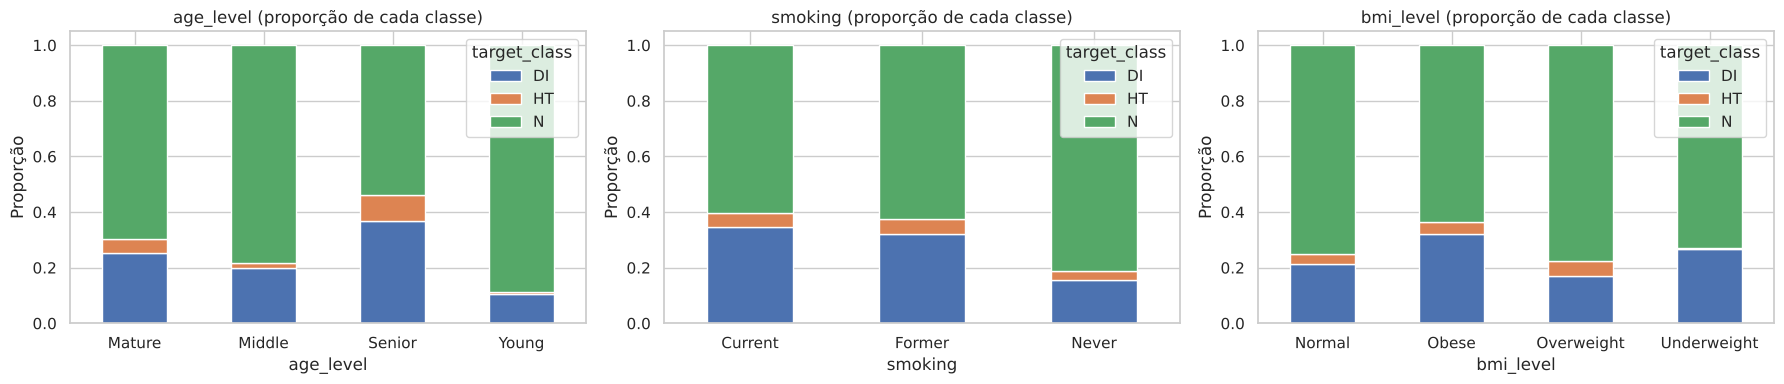

In [3]:
rows = []
for c in CAT_COLS:
    table = pd.crosstab(df[c], df['target_class'])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    rows.append({'Feature': c, 'chi2': chi2, 'gl': dof, 'p-value': p, 'V de Cramér': v})
cat_vs_class = pd.DataFrame(rows).sort_values('V de Cramér', ascending=False).reset_index(drop=True)
display(cat_vs_class.style.format({'chi2': '{:.1f}', 'p-value': '{:.2g}', 'V de Cramér': '{:.3f}'}))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, c in zip(axes, cat_vs_class['Feature'][:3]):
    pd.crosstab(df[c], df['target_class'], normalize='index').plot(kind='bar', stacked=True, ax=ax)
    ax.set_title(f'{c} (proporção de cada classe)'); ax.set_ylabel('Proporção'); ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

**Conclusões:**
- Todas as associações são **fracas** (V < 0.2). A mais forte é `age_level` (que repete a informação de `age`), seguida de **`smoking`**, que o notebook principal não menciona na EDA.
- **`employment_status` não tem associação significativa** com `target_class` (p > 0.05). É a candidata mais clara a feature **não informativa** entre as categóricas, como pede o enunciado.
- `stress_level` e `high_ldl_cholesterol` são significativas a 5% mas com V ≤ 0.06: na prática, irrelevantes.

### 1.2 Features categóricas e `target_class` vs `target_regression`

Para relacionar uma variável categórica com um alvo contínuo usamos a **ANOVA a um fator** e o $\eta^2$
(proporção da variância de `target_regression` explicada pelos grupos).

,Feature,F,p-value,eta²
0,target_class,17.77,2.2e-08,0.0175
1,age_level,2.09,0.1,0.0031
2,sugar_consumption,1.33,0.26,0.0013
3,bmi_level,0.80,0.49,0.0012
4,stress_level,0.91,0.4,0.0009
5,family_history,1.67,0.2,0.0008
6,physical_activity,0.31,0.74,0.0003
7,education_level,0.23,0.8,0.0002
8,low_hdl_cholesterol,0.41,0.52,0.0002
9,high_ldl_cholesterol,0.24,0.62,0.0001


,count,mean,std,min,25%,50%,75%,max
target_class,,,,,,,,
DI,467.0,145.4,43.8,70.0,114.5,141.0,170.5,300.0
HT,83.0,134.8,32.9,80.0,112.5,140.0,158.0,200.0
N,1450.0,133.6,34.9,70.0,100.0,140.0,159.0,200.0


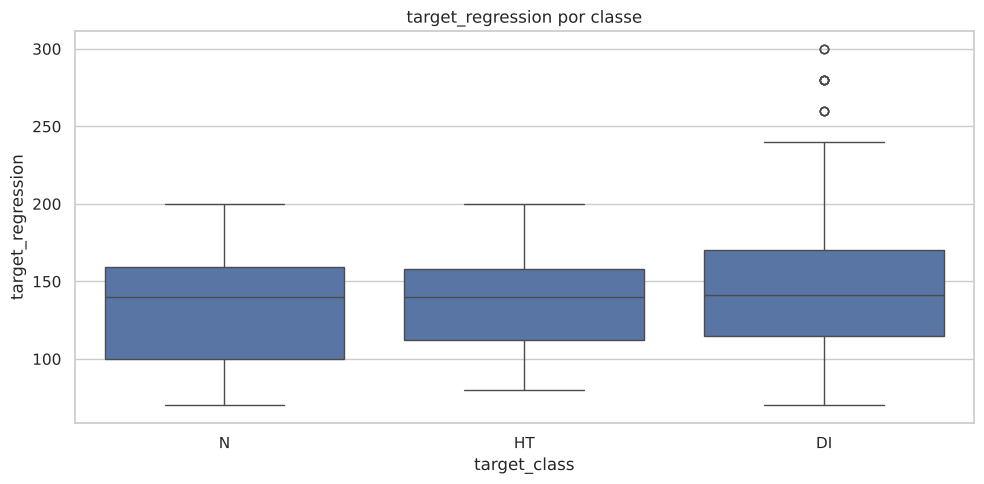

In [4]:
rows = []
gm = df['target_regression'].mean(); sst = ((df['target_regression'] - gm) ** 2).sum()
for c in CAT_COLS + ['target_class']:
    groups = [g['target_regression'].values for _, g in df.groupby(c)]
    F, p = stats.f_oneway(*groups)
    ssb = sum(len(g) * (g.mean() - gm) ** 2 for g in groups)
    rows.append({'Feature': c, 'F': F, 'p-value': p, 'eta²': ssb / sst})
cat_vs_reg = pd.DataFrame(rows).sort_values('eta²', ascending=False).reset_index(drop=True)
display(cat_vs_reg.style.format({'F': '{:.2f}', 'p-value': '{:.2g}', 'eta²': '{:.4f}'}))
display(df.groupby('target_class')['target_regression'].describe().round(1))

sns.boxplot(data=df, x='target_class', y='target_regression', order=['N', 'HT', 'DI'])
plt.title('target_regression por classe'); plt.tight_layout(); plt.show()

**Conclusões:**
- **Nenhuma** feature categórica tem associação significativa com `target_regression` (todos os p > 0.05).
- A única variável associada é o **outro alvo**, `target_class`: os doentes DI têm valores médios mais altos (≈145 vs ≈134) e só eles ultrapassam 200. Mesmo assim, a classe explica menos de 2% da variância ($\eta^2 \approx 0.018$).
- Isto reforça a conclusão do notebook principal: `target_regression` é praticamente independente de todas as features disponíveis.

### 1.3 Duas fontes de dados: pacientes "medidos" vs "imputados"

O notebook principal observa que vários histogramas têm um pico central dominante e atribui-o a imputação. Investigámos
isto **linha a linha**: os valores medidos são números "redondos" (no máximo 2 casas decimais, ex.: `245.0`, `6.3`),
enquanto os valores imputados têm muitas casas decimais (ex.: `225.071183`). Contamos, para cada paciente, quantas das
10 features com este padrão têm valores com mais de 2 casas decimais.

In [5]:
IMPUTABLE = ['cholesterol', 'sleep_hours', 'triglycerides', 'systolic_bp', 'diastolic_bp',
             'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl']
many_decimals = pd.DataFrame({c: (df[c] * 100 - (df[c] * 100).round()).abs() > 1e-6 for c in IMPUTABLE})
n_imputed = many_decimals.sum(axis=1)
print('N.º de features com valor "imputado" por paciente vs classe:')
display(pd.crosstab(n_imputed, df['target_class'], margins=True))

df['measured'] = (n_imputed == 0).astype(int)
print('Proporção de pacientes "medidos" por classe:')
display(df.groupby('target_class')['measured'].agg(['sum', 'mean']).rename(columns={'sum': 'n medidos', 'mean': 'proporção'}).round(3))

N.º de features com valor "imputado" por paciente vs classe:


target_class,DI,HT,N,All
row_0,,,,
0,344,0,362,706
7,0,0,1,1
8,37,18,32,87
9,6,1,92,99
10,80,64,963,1107
All,467,83,1450,2000


Proporção de pacientes "medidos" por classe:


,n medidos,proporção
target_class,,
DI,344,0.737
HT,0,0.000
N,362,0.250


O padrão é claro e **por linha**: cada paciente tem ou **todas** as 10 medições reais (0 imputadas) ou quase todas imputadas
(8 a 10). O dataset parece ser a junção de **duas fontes**:

| Fonte | Pacientes | DI | HT | N |
|---|---|---|---|---|
| Medidos | 706 | 344 | **0** | 362 |
| Imputados | 1294 | 123 | 83 | 1088 |

**Nenhum doente HT tem medições reais**, e 74% dos DI são "medidos", contra 25% dos N. Ou seja, **a fonte dos dados está
fortemente associada à classe**. Isto pode criar associações que não são clínicas. Comparamos cada feature entre classes
**dentro** de cada fonte (teste de Kruskal-Wallis nos medidos).

,Medidos DI,Medidos N,p (medidos),Imputados DI,Imputados HT,Imputados N
Feature,,,,,,
HbA1c_level,6.948910,5.396848,6.4e-117,6.804854,5.398540,5.700000
age,57.500000,56.000000,0.64,60.000000,66.000000,39.000000
bmi,27.250000,27.400000,0.43,29.250000,27.320000,27.320000
triglycerides,157.000000,154.000000,0.84,234.895522,244.350515,246.703704
cholesterol,227.000000,222.500000,0.2,224.970455,224.148026,225.297062
systolic_bp,135.000000,135.500000,0.73,134.682081,134.392491,134.102666
hdl,65.000000,68.000000,0.81,64.360525,64.573454,64.753020
crp_level,7.458483,7.369123,0.63,7.582981,7.575283,7.462859
homocysteine_level,12.416838,12.549093,2.4e-09,12.384471,12.508636,12.508636


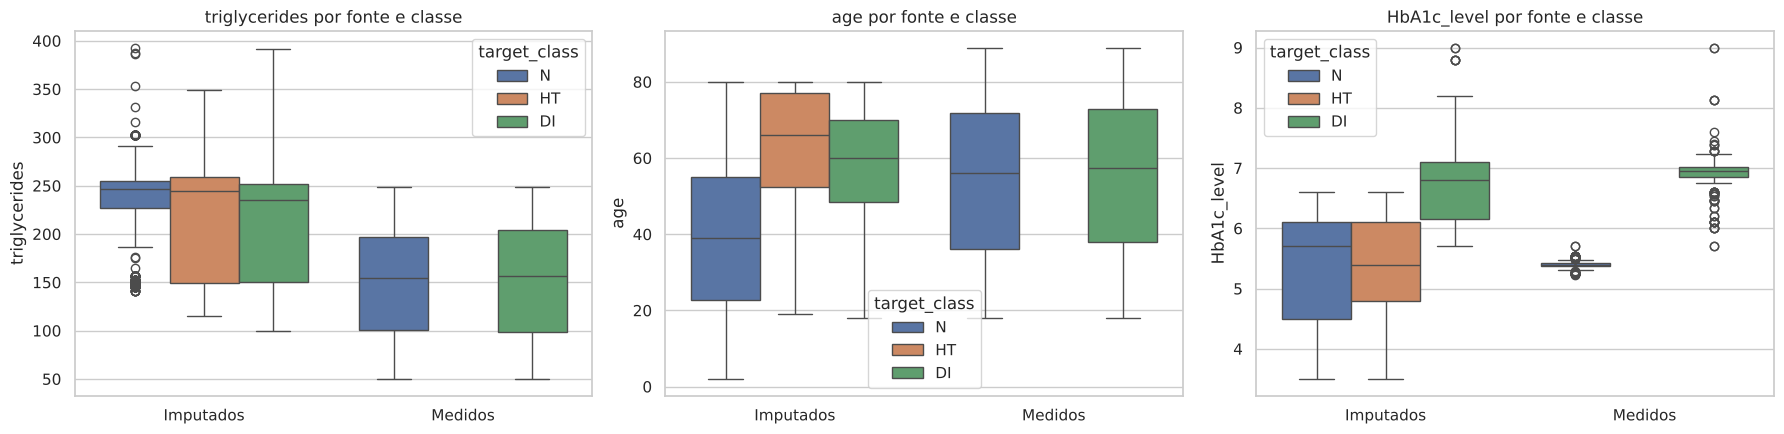

In [6]:
rows = []
for c in ['HbA1c_level', 'age', 'bmi', 'triglycerides', 'cholesterol', 'systolic_bp', 'hdl', 'crp_level', 'homocysteine_level']:
    med = df[df.measured == 1].groupby('target_class')[c].median()
    imp = df[df.measured == 0].groupby('target_class')[c].median()
    p = stats.kruskal(*[g[c] for _, g in df[df.measured == 1].groupby('target_class')]).pvalue
    rows.append({'Feature': c, 'Medidos DI': med['DI'], 'Medidos N': med['N'], 'p (medidos)': p,
                 'Imputados DI': imp['DI'], 'Imputados HT': imp['HT'], 'Imputados N': imp['N']})
display(pd.DataFrame(rows).set_index('Feature').style.format('{:.2f}').format({'p (medidos)': '{:.2g}'}))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
src = df['measured'].map({1: 'Medidos', 0: 'Imputados'})
for ax, c in zip(axes, ['triglycerides', 'age', 'HbA1c_level']):
    sns.boxplot(x=src, y=df[c], hue=df['target_class'], hue_order=['N', 'HT', 'DI'], ax=ax)
    ax.set_title(f'{c} por fonte e classe'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

**Conclusões (importantes para a interpretação de todo o trabalho):**

1. **`triglycerides` não distingue DI de N quando se compara dentro da mesma fonte** (medidos: medianas 157 vs 154, p ≈ 0.84).
   O "padrão contraintuitivo" assinalado no notebook principal (N com triglicéridos mais altos do que DI) **é um artefacto
   da junção das fontes**: os DI são sobretudo pacientes medidos (≈155) e os N sobretudo imputados (≈245). Por isso, quando
   o Ridge e o Lasso colocam `triglycerides` no top-3, o modelo está, em grande parte, a identificar **a fonte**, e não um efeito clínico.
2. **`age`** também não difere entre DI e N nos medidos (p ≈ 0.64). A diferença global vem de os N imputados serem jovens (mediana 39 anos).
   Já entre HT e N (ambos só na fonte imputada) a idade é relevante: os HT são mais velhos.
3. **`HbA1c_level`** é a única feature com um efeito forte e consistente nas duas fontes. Nos medidos separa DI de N **na perfeição**
   (ver 3.4): nenhum N medido tem HbA1c ≥ 6.5%, que é o critério clínico de diabetes.
4. **Correção à EDA principal (boxplots):** `bmi` **não** discrimina DI. As médias são DI 27.8, HT 28.2 e N 26.8 (r = 0.06 com DI), ou seja, quem tem o valor mais alto é HT.

In [7]:
print(df.groupby('target_class')['bmi'].agg(['mean', 'median']).round(2))
print(f"r(bmi, is_DI) = {np.corrcoef(df['bmi'], df['target_class'] == 'DI')[0, 1]:.3f}")

               mean  median
target_class               
DI            27.84   27.60
HT            28.22   27.32
N             26.80   27.32
r(bmi, is_DI) = 0.061


### 1.4 Multicolinearidade com as features categóricas (GVIF)

O notebook principal calcula o VIF apenas nas features numéricas e conclui que não há multicolinearidade. Mas `age_level`
e `bmi_level` são **discretizações** de `age` e `bmi`, por isso é de esperar redundância entre elas.

Calcular o VIF de cada dummy individualmente **não é fiável**: o valor depende da categoria escolhida como referência no
`drop_first`. A medida adequada para variáveis categóricas com várias dummies é o **GVIF** (*Generalized VIF*, Fox & Monette, 1992),
calculado para o bloco completo de dummies de cada variável. Para comparar variáveis com diferentes graus de liberdade usa-se
$GVIF^{1/(2\cdot gl)}$, que está na escala de $\sqrt{VIF}$ (os limiares VIF 5 e 10 correspondem a 2.24 e 3.16).

In [8]:
TERMS = {c: [f for f in FEATURES if f.startswith(c + '_')] for c in CAT_COLS}
NUM_FEATS = [f for f in FEATURES if not any(f in v for v in TERMS.values())]

def gvif_table(cols_by_term):
    X = df_enc[[c for cols in cols_by_term.values() for c in cols]].astype(float)
    R = np.corrcoef(X.values, rowvar=False); names = list(X.columns); det_R = np.linalg.det(R)
    rows = []
    for term, cols in cols_by_term.items():
        i = [names.index(c) for c in cols]; j = [k for k in range(len(names)) if k not in i]
        g = np.linalg.det(R[np.ix_(i, i)]) * np.linalg.det(R[np.ix_(j, j)]) / det_R
        rows.append({'Variável': term, 'gl': len(cols), 'GVIF': g, 'GVIF^(1/2gl)': g ** (1 / (2 * len(cols)))})
    return pd.DataFrame(rows).sort_values('GVIF^(1/2gl)', ascending=False).reset_index(drop=True)

blocks = {**{n: [n] for n in NUM_FEATS}, **TERMS}
print('Todas as features:'); display(gvif_table(blocks).head(6).round(3))
blocks_red = {k: v for k, v in blocks.items() if k not in ['age_level', 'bmi_level']}
print('Sem age_level e bmi_level:'); display(gvif_table(blocks_red).head(4).round(3))

r2_age = sm.OLS(df_enc['age'], sm.add_constant(df_enc[TERMS['age_level']])).fit().rsquared
r2_bmi = sm.OLS(df_enc['bmi'], sm.add_constant(df_enc[TERMS['bmi_level']])).fit().rsquared
print(f'R² de age explicado por age_level: {r2_age:.3f} | R² de bmi explicado por bmi_level: {r2_bmi:.3f}')

Todas as features:


,Variável,gl,GVIF,GVIF^(1/2gl)
0,age,1,13.277,3.644
1,bmi,1,7.264,2.695
2,age_level,3,21.220,1.664
3,bmi_level,3,11.534,1.503
4,high_ldl_cholesterol,1,1.801,1.342
5,triglycerides,1,1.652,1.285


Sem age_level e bmi_level:


,Variável,gl,GVIF,GVIF^(1/2gl)
0,high_ldl_cholesterol,1,1.679,1.296
1,triglycerides,1,1.591,1.261
2,ldl,1,1.512,1.230
3,low_hdl_cholesterol,1,1.432,1.197


R² de age explicado por age_level: 0.921 | R² de bmi explicado por bmi_level: 0.859


Demonstração de que o VIF de cada dummy depende da categoria de referência (o de `age`, numérica, não depende):

In [9]:
for ref in ['Mature', 'Young']:
    d = pd.get_dummies(df_clean['age_level'], dtype=float).drop(columns=ref)
    Xr = pd.concat([df_enc[NUM_FEATS].astype(float), d], axis=1); Xc = sm.add_constant(Xr).values
    vifs = {c: round(variance_inflation_factor(Xc, list(Xr.columns).index(c) + 1), 2) for c in list(d.columns) + ['age']}
    print(f'Referência = {ref:6s} ->', vifs)

Referência = Mature -> {'Middle': np.float64(3.98), 'Senior': np.float64(3.21), 'Young': np.float64(8.05), 'age': np.float64(13.08)}
Referência = Young  -> {'Mature': np.float64(11.73), 'Middle': np.float64(4.22), 'Senior': np.float64(18.64), 'age': np.float64(13.08)}


**Conclusões:**
- Com as categóricas incluídas, **`age` tem VIF ≈ 13 (> 10) e `bmi` ≈ 7 (> 5)**: há multicolinearidade, causada por
  `age_level` (explica 92% da variância de `age`) e `bmi_level` (86% de `bmi`). A conclusão "não existe multicolinearidade" do notebook principal só é válida para as numéricas.
- Retirando `age_level` e `bmi_level`, todos os GVIF descem para < 1.7.
- Na secção 4 verificamos que retirar estas features derivadas **não piora** a classificação. Pelo princípio da parcimónia, há
  razões para as remover (ou, em alternativa, remover as versões contínuas).
- Isto explica também porque é que, no Ridge do notebook principal, a importância da idade aparece "dividida" entre `age`, `age_level_Middle` e `age_level_Young`.

---
## 2. Regressão complementar

### 2.1 Testes de significância (OLS)

O notebook principal avalia os modelos só por R², MAE e RMSE. A teoria (T2) usa também **testes de hipóteses**: o teste *t* para
cada coeficiente e o teste *F* global ($H_0: \beta_1 = \dots = \beta_p = 0$, ou seja, nenhuma feature tem relação com o alvo).

In [10]:
ols_slr = sm.OLS(y_reg, sm.add_constant(df_enc[['HbA1c_level']])).fit()
ols_all = sm.OLS(y_reg, sm.add_constant(df_enc[FEATURES].astype(float))).fit()
print(ols_slr.summary().tables[1])
print(f"\nSimple LR (HbA1c):  R²={ols_slr.rsquared:.4f}  | p-value do coeficiente = {ols_slr.pvalues['HbA1c_level']:.2g}")
print(f"Multiple LR (40):   R²={ols_all.rsquared:.4f}  R² ajustado={ols_all.rsquared_adj:.4f}  F={ols_all.fvalue:.3f}  p(F)={ols_all.f_pvalue:.3f}")
print('\nCoeficientes com p < 0.05 no modelo com 40 features:')
print(ols_all.pvalues.drop('const')[lambda s: s < 0.05].round(4))

                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const         114.4021      4.674     24.474      0.000     105.235     123.569
HbA1c_level     3.8557      0.805      4.788      0.000       2.277       5.435

Simple LR (HbA1c):  R²=0.0113  | p-value do coeficiente = 1.8e-06
Multiple LR (40):   R²=0.0243  R² ajustado=0.0044  F=1.219  p(F)=0.164

Coeficientes com p < 0.05 no modelo com 40 features:
HbA1c_level           0.0000
family_history_Yes    0.0461
dtype: float64


**Conclusões:**
- **Modelo com as 40 features:** o teste F global tem p ≈ 0.16, por isso **não se rejeita $H_0$**. Não há evidência de que
  o conjunto das features explique `target_regression`, e o R² ajustado é praticamente 0.
- **`HbA1c_level` sozinho:** o coeficiente é **estatisticamente significativo** (p ≈ 2e-6), mas o R² é ≈ 0.011. Com n = 2000, até um efeito minúsculo
  se torna significativo: **significância estatística ≠ relevância prática**. Por cada ponto percentual de HbA1c, o alvo sobe ≈ 3.9 unidades,
  para um desvio-padrão do alvo de ≈ 37.

### 2.2 Análise de resíduos (Simple LR com `HbA1c_level`)

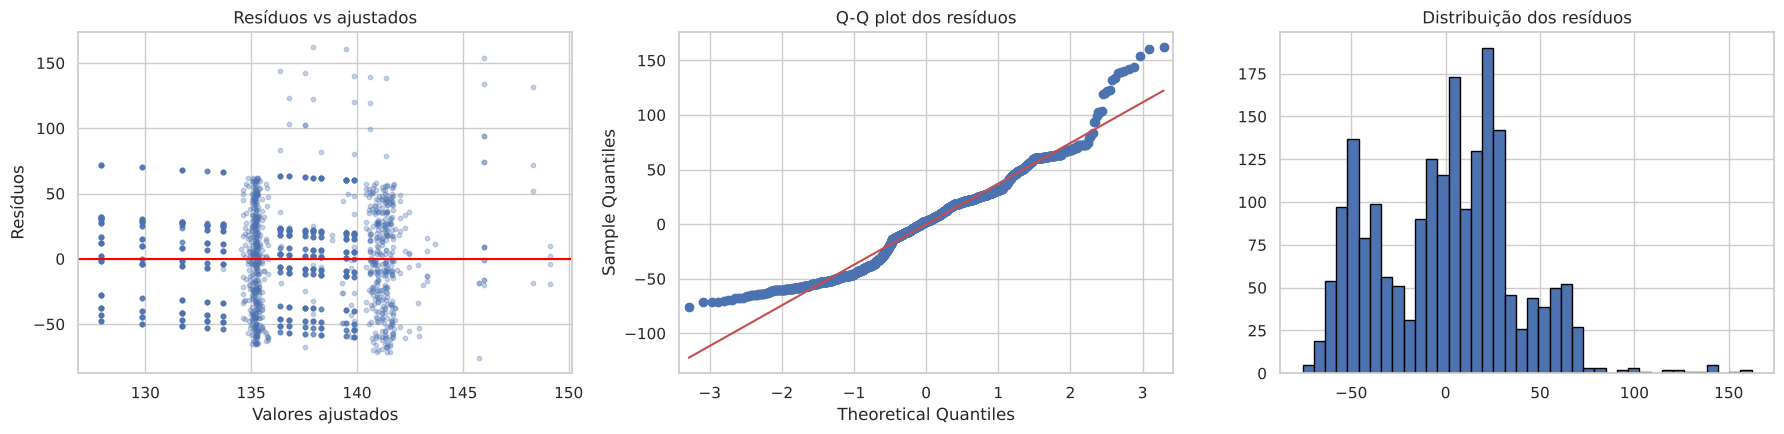

Jarque-Bera (normalidade): p = 2.2e-09
Breusch-Pagan (homocedasticidade): p = 1.4e-05


In [11]:
fitted, resid = ols_slr.fittedvalues, ols_slr.resid
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].scatter(fitted, resid, alpha=0.3, s=10); axes[0].axhline(0, color='red')
axes[0].set_xlabel('Valores ajustados'); axes[0].set_ylabel('Resíduos'); axes[0].set_title('Resíduos vs ajustados')
sm.qqplot(resid, line='s', ax=axes[1]); axes[1].set_title('Q-Q plot dos resíduos')
axes[2].hist(resid, bins=40, edgecolor='black'); axes[2].set_title('Distribuição dos resíduos')
plt.tight_layout(); plt.show()

print(f'Jarque-Bera (normalidade): p = {stats.jarque_bera(resid).pvalue:.2g}')
print(f'Breusch-Pagan (homocedasticidade): p = {het_breuschpagan(resid, ols_slr.model.exog)[1]:.2g}')

**Conclusões:** os resíduos **não são normais** (Jarque-Bera p < 0.001; cauda direita com os valores > 200 dos DI) e são
**heterocedásticos** (Breusch-Pagan p < 0.001: a dispersão aumenta para HbA1c altos). Os pressupostos da regressão linear
não se verificam, pelo que os p-values devem ser lidos com cautela. Ainda assim, isto não altera a conclusão: o modelo não tem capacidade preditiva.

### 2.3 Alternativas testadas (para descartar)

Para garantir que o R² ≈ 0 não se deve a uma má escolha de features ou de modelo, testámos várias alternativas com
**validação cruzada 5-fold repetida 5 vezes** (25 estimativas). Incluímos modelos **não lineares** (Random Forest, Gradient Boosting,
kNN) apenas como **controlo**: se também tiverem R² ≈ 0, a falta de sinal não é uma limitação da linearidade.

In [12]:
cv_reg = RepeatedKFold(n_splits=5, n_repeats=5, random_state=0)
lin = lambda: make_pipeline(StandardScaler(), LinearRegression())
E = df_enc.copy()
cls_dummies = pd.get_dummies(df['target_class'], prefix='cls', drop_first=True, dtype=int)
E = pd.concat([E, cls_dummies], axis=1); E['measured'] = df['measured']
E['HbA1c_x_DI'] = E['HbA1c_level'] * (df['target_class'] == 'DI')
CLS = list(cls_dummies.columns)
NUM_TOP = ['HbA1c_level', 'age', 'bmi', 'sleep_hours', 'systolic_bp']

experiments = [
    ('Simple LR: HbA1c_level',                    lin(), ['HbA1c_level']),
    ('MLR: HbA1c + age (top-2 do principal)',      lin(), ['HbA1c_level', 'age']),
    ('MLR: todas (40)',                            lin(), FEATURES),
    ('MLR: só numéricas (18)',                     lin(), NUM_FEATS),
    ('Polinomial grau 2: HbA1c',                   make_pipeline(PolynomialFeatures(2), StandardScaler(), LinearRegression()), ['HbA1c_level']),
    ('Polinomial grau 2: 5 numéricas',             make_pipeline(PolynomialFeatures(2), StandardScaler(), LinearRegression()), NUM_TOP),
    ('log(alvo): HbA1c + age',                     TransformedTargetRegressor(lin(), func=np.log, inverse_func=np.exp), ['HbA1c_level', 'age']),
    ('RidgeCV: todas',                             make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 30))), FEATURES),
    ('LassoCV: todas',                             make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=0)), FEATURES),
    ('MLR: só target_class (outro alvo)',          lin(), CLS),
    ('MLR: HbA1c + target_class',                  lin(), ['HbA1c_level'] + CLS),
    ('MLR: HbA1c + target_class + interação',      lin(), ['HbA1c_level', 'HbA1c_x_DI'] + CLS),
    ('MLR: todas + target_class + fonte',          lin(), FEATURES + CLS + ['measured']),
    ('[controlo] Random Forest: todas',            RandomForestRegressor(300, min_samples_leaf=10, random_state=0, n_jobs=-1), FEATURES),
    ('[controlo] Gradient Boosting: todas',        GradientBoostingRegressor(max_depth=2, n_estimators=150, learning_rate=0.05, random_state=0), FEATURES),
    ('[controlo] kNN (k=25): 4 numéricas',         make_pipeline(StandardScaler(), KNeighborsRegressor(25)), ['HbA1c_level', 'age', 'bmi', 'triglycerides']),
]
rows = []
for name, model, feats in experiments:
    s = cross_val_score(model, E[feats], y_reg, cv=cv_reg, scoring='r2')
    rows.append({'Modelo': name, 'n features': len(feats), 'R² (CV) média': s.mean(), 'R² (CV) std': s.std()})
reg_alt = pd.DataFrame(rows)
display(reg_alt.style.format({'R² (CV) média': '{:+.4f}', 'R² (CV) std': '{:.4f}'}))

,Modelo,n features,R² (CV) média,R² (CV) std
0,Simple LR: HbA1c_level,1,+0.0076,0.0113
1,MLR: HbA1c + age (top-2 do principal),2,+0.0085,0.0120
2,MLR: todas (40),40,-0.0231,0.0158
3,MLR: só numéricas (18),18,-0.0058,0.0168
4,Polinomial grau 2: HbA1c,1,+0.0119,0.0144
5,Polinomial grau 2: 5 numéricas,5,+0.0056,0.0158
6,log(alvo): HbA1c + age,2,-0.0104,0.0158
7,RidgeCV: todas,40,-0.0024,0.0054
8,LassoCV: todas,40,+0.0050,0.0071
9,MLR: só target_class (outro alvo),2,+0.0134,0.0118


In [13]:
print('Correlação HbA1c_level vs target_regression dentro de cada classe:')
for k in ['DI', 'HT', 'N']:
    m = df['target_class'] == k
    r, p = stats.pearsonr(df.loc[m, 'HbA1c_level'], df.loc[m, 'target_regression'])
    print(f'  {k:2s} (n={m.sum():4d}): r = {r:+.3f}  (p = {p:.2f})')

Correlação HbA1c_level vs target_regression dentro de cada classe:
  DI (n= 467): r = -0.006  (p = 0.89)
  HT (n=  83): r = +0.133  (p = 0.23)
  N  (n=1450): r = +0.033  (p = 0.20)


**Conclusões:**
- **Nenhuma** das 16 alternativas ultrapassa R² ≈ 0.014, incluindo os modelos não lineares de controlo. A ausência de sinal
  **não é uma limitação dos modelos lineares**: as features disponíveis simplesmente não explicam `target_regression`.
  (Isto corrige uma frase da conclusão do notebook principal, que sugere que modelos não lineares "poderiam capturar relações".)
- **Dentro de cada classe, a correlação entre HbA1c e o alvo é nula** (DI: r ≈ −0.01). O pouco sinal da HbA1c existe só porque os DI
  têm HbA1c **e** alvo mais altos. Por isso, o modelo "só `target_class`" tem o mesmo R² que "HbA1c + `target_class`": a HbA1c funciona como *proxy* da classe.
- Usar `target_class` como preditor da regressão não é legítimo num cenário real (é o outro alvo) e, mesmo assim, não ajuda.

---
## 3. Classificação complementar

### 3.1 Variância **das estimativas** de cada método de reamostragem

O enunciado pede para indicar *como a variância é afetada pelos métodos de reamostragem*. O notebook principal compara o
**desvio-padrão entre folds/iterações** de cada método. Esta medida não responde à pergunta, porque depende do tamanho de cada
fold de teste (com k=10 cada fold é mais pequeno, logo mais ruidoso), e não da fiabilidade da **estimativa final**.

A pergunta relevante (slides T4, *"the evaluation estimate itself has variance"*) é: **se repetíssemos o procedimento com outra
partição aleatória, quanto mudaria o resultado reportado?** Para o medir, repetimos cada método **20 vezes** com sementes
diferentes e calculamos o desvio-padrão das 20 estimativas finais de F1 macro.

O **LOOCV** não entra nesta comparação: é determinístico (só há uma forma de deixar um de fora), por isso repeti-lo dá sempre o mesmo valor.
A teoria diz que tem viés quase nulo mas variância alta como estimador, porque os n modelos treinam em conjuntos quase idênticos e os erros ficam muito correlacionados.

*(Esta célula demora alguns minutos.)*

,Modelo,Método,Média,Desvio-padrão da estimativa,Mín,Máx
0,Logistic Regression,Holdout 80/20,0.6209,0.0195,0.5957,0.6568
1,Logistic Regression,CV k=5,0.6145,0.0058,0.6065,0.6251
2,Logistic Regression,CV k=10,0.6123,0.0051,0.6068,0.6255
3,Logistic Regression,Bootstrap (B=50),0.6204,0.0033,0.6130,0.6277
4,LDA,Holdout 80/20,0.6214,0.0294,0.5850,0.6951
5,LDA,CV k=5,0.6212,0.0109,0.6012,0.6464
6,LDA,CV k=10,0.6220,0.0098,0.6025,0.6419
7,LDA,Bootstrap (B=50),0.6220,0.0047,0.6133,0.6323


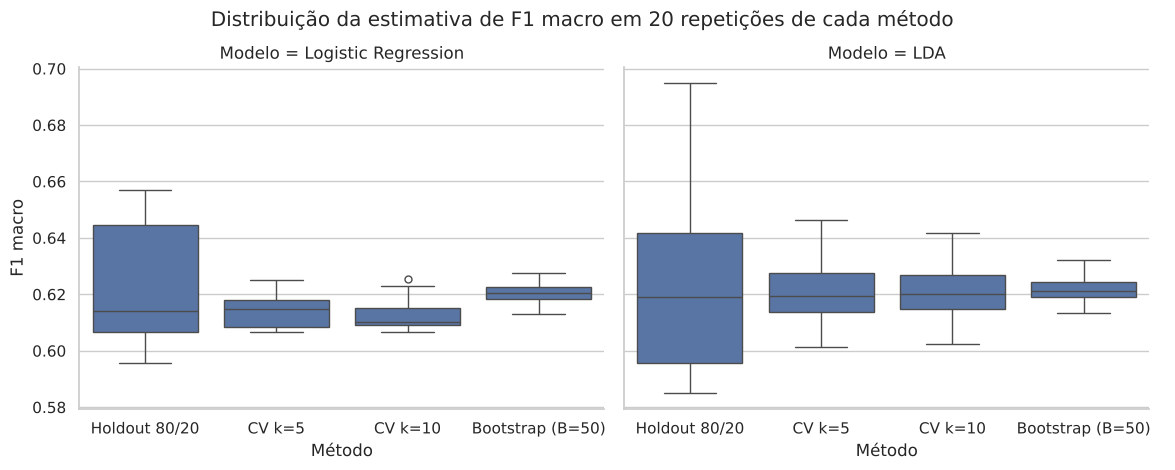

In [14]:
N_REPEATS, B = 20, 50
models_cmp = {'Logistic Regression': lambda: LogisticRegression(max_iter=1000),
              'LDA': lambda: LinearDiscriminantAnalysis()}
pipe = lambda mk: make_pipeline(StandardScaler(), mk())

def holdout_est(mk, seed):
    Xtr, Xte, ytr, yte = train_test_split(X_all, y_class, test_size=0.2, stratify=y_class, random_state=seed)
    return f1_score(yte, pipe(mk).fit(Xtr, ytr).predict(Xte), average='macro')

def cv_est(mk, k, seed):
    cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    return cross_val_score(pipe(mk), X_all, y_class, cv=cv, scoring='f1_macro').mean()

def bootstrap_est(mk, seed):
    rng, n, scores = np.random.RandomState(1000 + seed), len(y_class), []
    for _ in range(B):
        idx = rng.randint(0, n, n); oob = np.setdiff1d(np.arange(n), idx)
        scores.append(f1_score(y_class[oob], pipe(mk).fit(X_all[idx], y_class[idx]).predict(X_all[oob]), average='macro'))
    return np.mean(scores)

var_rows, var_raw = [], []
for mname, mk in models_cmp.items():
    for method, fn in [('Holdout 80/20', lambda s: holdout_est(mk, s)),
                       ('CV k=5', lambda s: cv_est(mk, 5, s)),
                       ('CV k=10', lambda s: cv_est(mk, 10, s)),
                       (f'Bootstrap (B={B})', lambda s: bootstrap_est(mk, s))]:
        est = np.array([fn(s) for s in range(N_REPEATS)])
        var_raw += [{'Modelo': mname, 'Método': method, 'F1 macro': e} for e in est]
        var_rows.append({'Modelo': mname, 'Método': method, 'Média': est.mean(),
                         'Desvio-padrão da estimativa': est.std(ddof=1), 'Mín': est.min(), 'Máx': est.max()})
var_df = pd.DataFrame(var_rows)
display(var_df.style.format({c: '{:.4f}' for c in ['Média', 'Desvio-padrão da estimativa', 'Mín', 'Máx']}))

g = sns.catplot(data=pd.DataFrame(var_raw), x='Método', y='F1 macro', col='Modelo', kind='box', height=4.5, aspect=1.3)
g.fig.suptitle(f'Distribuição da estimativa de F1 macro em {N_REPEATS} repetições de cada método', y=1.04)
plt.show()

**Conclusões:**
- O **Holdout** é o método com **maior variância**: a estimativa muda bastante consoante a partição (desvio-padrão ≈3 vezes
  superior ao do CV k=5). Com apenas 17 casos de HT no teste, acertar ou falhar 1 ou 2 casos altera muito o F1 macro.
- **CV k=5 e k=10 têm variância semelhante e muito menor**. O k=10 tem variância **igual ou ligeiramente inferior** à do k=5, ao
  contrário do que o notebook principal sugere (o que aumenta com k é a dispersão *entre folds*, não a incerteza da média final).
- O **Bootstrap** com B=50 é o mais estável, porque faz a média de muitas estimativas OOB. Em contrapartida, cada modelo treina só com
  ≈63.2% de observações distintas, o que tende a tornar a estimativa pessimista (viés).
- **As médias dos quatro métodos são praticamente iguais** (≈0.61–0.62): os métodos diferem sobretudo na **variância** e no custo computacional, não no valor esperado.
- O LDA tem sistematicamente mais variância do que a LR.

### 3.2 Métricas adequadas a classes desequilibradas

O F1 macro é uma boa métrica principal, mas depende do limiar de decisão (0.5 por omissão). Acrescentamos:
- **Balanced accuracy:** média do recall de cada classe. Um classificador que preveja sempre N obtém 1/3.
- **AUC one-vs-rest:** mede a capacidade de **ordenar** os pacientes por probabilidade, independentemente do limiar (slides T4, curvas ROC).
- **Recall por classe:** mostra diretamente quantos doentes de cada classe são detetados.

Avaliação com CV estratificada 5-fold (o melhor compromisso, segundo a secção anterior).

In [15]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
CLASS_NAMES = ['DI', 'HT', 'N']

def full_report(name, model, X=X_all):
    proba = cross_val_predict(model, X, y_class, cv=cv5, method='predict_proba')
    pred = proba.argmax(axis=1)
    rec = recall_score(y_class, pred, average=None)
    return {'Modelo': name, 'Accuracy': accuracy_score(y_class, pred), 'F1 macro': f1_score(y_class, pred, average='macro'),
            'Balanced acc.': balanced_accuracy_score(y_class, pred), 'AUC (ovr)': roc_auc_score(y_class, proba, multi_class='ovr'),
            **{f'Recall {c}': r for c, r in zip(CLASS_NAMES, rec)}}, pred, proba

rep_lr, pred_lr, proba_lr = full_report('Logistic Regression', pipe(models_cmp['Logistic Regression']))
rep_lda, pred_lda, _ = full_report('LDA', pipe(models_cmp['LDA']))
display(pd.DataFrame([rep_lr, rep_lda]).set_index('Modelo').round(3))
print('AUC one-vs-rest por classe (LR):', {c: round(roc_auc_score(y_class == k, proba_lr[:, k]), 3) for k, c in enumerate(CLASS_NAMES)})

,Accuracy,F1 macro,Balanced acc.,AUC (ovr),Recall DI,Recall HT,Recall N
Modelo,,,,,,,
Logistic Regression,0.908,0.617,0.619,0.904,0.874,0.012,0.970
LDA,0.886,0.631,0.613,0.890,0.792,0.084,0.962


AUC one-vs-rest por classe (LR): {'DI': 0.978, 'HT': 0.797, 'N': 0.937}


**Conclusões:** a **AUC da classe HT é ≈ 0.80**, bem acima de 0.5. Os modelos **ordenam** razoavelmente os doentes HT
(atribuem-lhes probabilidades de HT mais altas do que aos restantes), mas essas probabilidades nunca chegam a ser a maior das três, por causa do
prior baixo (4%). O problema da HT **não é só de separabilidade, é sobretudo do limiar de decisão**, o que se pode corrigir.

### 3.3 Tratamento do desequilíbrio de classes

O notebook principal sugere SMOTE ou `class_weight='balanced'` como trabalho futuro. Testamos quatro abordagens, todas avaliadas
com a mesma CV estratificada 5-fold:

1. **Logistic Regression com `class_weight='balanced'`:** pesa cada observação de forma inversamente proporcional à frequência da classe.
2. **LDA com priors iguais:** o LDA usa por omissão as proporções das classes como priors $\pi_k$ no teorema de Bayes; com priors iguais (1/3), a decisão deixa de favorecer N.
3. **Random oversampling:** replica observações das classes minoritárias **só no treino de cada fold** (para não haver fuga de informação).
4. **Ajuste do limiar de decisão** (slides T3, *"lowering the decision threshold"*): multiplicamos as probabilidades de DI e HT por pesos
   $w_{DI}, w_{HT}$ e escolhemos a classe com maior valor. Os pesos são escolhidos para maximizar o F1 macro com uma **CV interna feita só no treino de cada fold**
   (validação aninhada). Assim, os dados de teste nunca influenciam a escolha.

In [16]:
class RandomOversampler(BaseEstimator, ClassifierMixin):
    # Replicates minority-class rows in the training data only, then fits the wrapped model
    def __init__(self, estimator=None, random_state=0):
        self.estimator, self.random_state = estimator, random_state
    def fit(self, X, y):
        rng = np.random.RandomState(self.random_state); n_max = np.bincount(y).max()
        idx = np.concatenate([rng.choice(np.where(y == k)[0], n_max, replace=True) for k in np.unique(y)])
        self.model_ = clone(self.estimator).fit(X[idx], y[idx]); self.classes_ = self.model_.classes_
        return self
    def predict(self, X): return self.model_.predict(X)
    def predict_proba(self, X): return self.model_.predict_proba(X)

class ThresholdTuned(BaseEstimator, ClassifierMixin):
    # Chooses class weights (w_DI, w_HT, w_N=1) applied to the predicted probabilities,
    # maximizing F1 macro with an inner CV on the training data only (nested validation)
    def __init__(self, estimator=None, grid=(1, 1.5, 2, 3, 4, 6, 8, 12)):
        self.estimator, self.grid = estimator, grid
    def fit(self, X, y):
        inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
        P = cross_val_predict(clone(self.estimator), X, y, cv=inner, method='predict_proba')
        best = max(((f1_score(y, (P * np.array([a, b, 1.0])).argmax(1), average='macro'), (a, b))
                    for a in self.grid for b in self.grid))
        self.weights_ = np.array([*best[1], 1.0])
        self.model_ = clone(self.estimator).fit(X, y); self.classes_ = self.model_.classes_
        return self
    def predict(self, X): return (self.model_.predict_proba(X) * self.weights_).argmax(1)
    def predict_proba(self, X):
        p = self.model_.predict_proba(X) * self.weights_; return p / p.sum(axis=1, keepdims=True)

candidates = {
    'LR (original)':               pipe(models_cmp['Logistic Regression']),
    'LDA (original)':              pipe(models_cmp['LDA']),
    'LR class_weight=balanced':    make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced')),
    'LDA priors iguais':           make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(priors=[1/3] * 3)),
    'LR + oversampling':           RandomOversampler(pipe(models_cmp['Logistic Regression'])),
    'LR + limiar ajustado (nested)':  ThresholdTuned(pipe(models_cmp['Logistic Regression'])),
    'LDA + limiar ajustado (nested)': ThresholdTuned(pipe(models_cmp['LDA'])),
}
imb_rows, imb_preds = [], {}
for name, model in candidates.items():
    proba = cross_val_predict(model, X_all, y_class, cv=cv5, method='predict_proba')
    pred = proba.argmax(axis=1)
    rec = recall_score(y_class, pred, average=None)
    imb_rows.append({'Modelo': name, 'Accuracy': accuracy_score(y_class, pred), 'F1 macro': f1_score(y_class, pred, average='macro'),
                     'Balanced acc.': balanced_accuracy_score(y_class, pred), 'AUC (ovr)': roc_auc_score(y_class, proba, multi_class='ovr'),
                     **{f'Recall {c}': r for c, r in zip(CLASS_NAMES, rec)}})
    imb_preds[name] = pred
imb_df = pd.DataFrame(imb_rows).set_index('Modelo')
display(imb_df.style.format('{:.3f}').highlight_max(axis=0, color='#c6efce'))

,Accuracy,F1 macro,Balanced acc.,AUC (ovr),Recall DI,Recall HT,Recall N
Modelo,,,,,,,
LR (original),0.908,0.617,0.619,0.904,0.874,0.012,0.970
LDA (original),0.886,0.631,0.613,0.890,0.792,0.084,0.962
LR class_weight=balanced,0.738,0.612,0.714,0.890,0.887,0.554,0.701
LDA priors iguais,0.752,0.614,0.716,0.883,0.852,0.566,0.730
LR + oversampling,0.729,0.604,0.702,0.882,0.872,0.542,0.693
LR + limiar ajustado (nested),0.867,0.679,0.699,0.901,0.861,0.337,0.899
LDA + limiar ajustado (nested),0.852,0.664,0.678,0.886,0.782,0.349,0.903


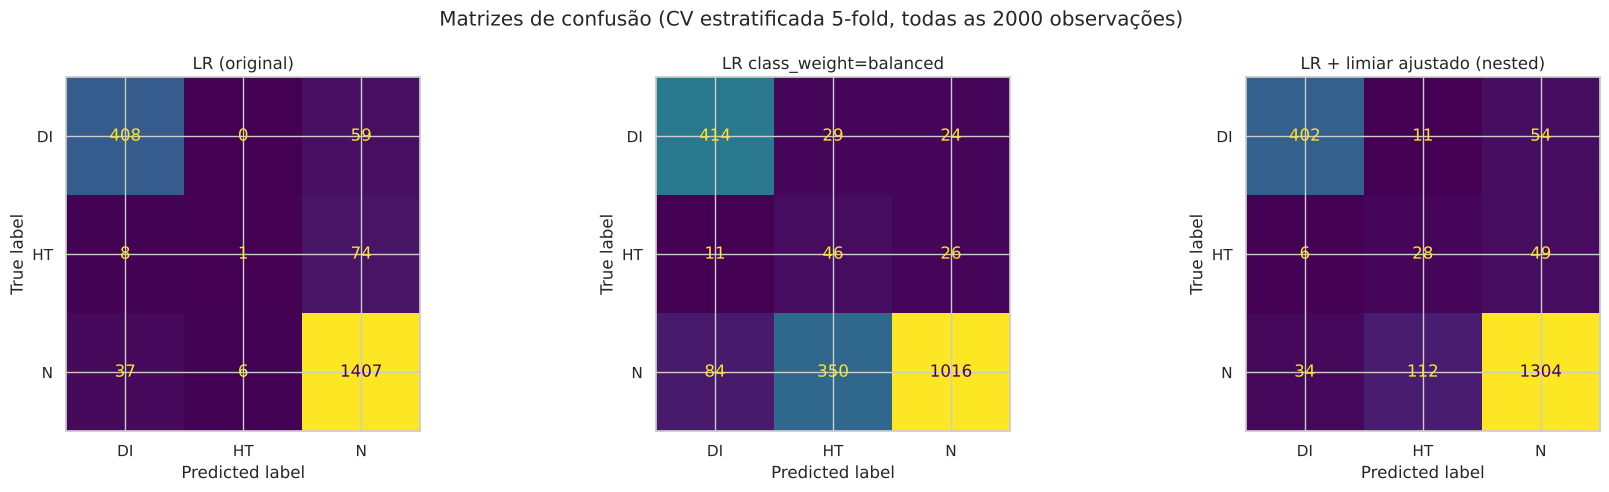

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, ['LR (original)', 'LR class_weight=balanced', 'LR + limiar ajustado (nested)']):
    ConfusionMatrixDisplay(confusion_matrix(y_class, imb_preds[name]), display_labels=CLASS_NAMES).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.suptitle('Matrizes de confusão (CV estratificada 5-fold, todas as 2000 observações)'); plt.tight_layout(); plt.show()

**Conclusões:**
- **O ajuste do limiar com validação aninhada é a melhor abordagem em F1 macro** (≈0.68 vs ≈0.62 na LR), com uma perda moderada de accuracy (≈0.87 vs ≈0.91) e recall de HT ≈0.34.
  É a única abordagem que melhora o F1 macro de forma clara, porque escolhe explicitamente o compromisso que maximiza essa métrica.
- **`class_weight='balanced'` e LDA com priors iguais** detetam mais de metade dos HT (recall ≈0.55 vs ≈0.01) e sobem a balanced accuracy para ≈0.71.
  O F1 macro fica igual, porque o ganho em HT é compensado pela perda de precisão (muitos N passam a ser classificados como HT) e a accuracy cai para ≈0.74.
- A AUC praticamente não muda: estas técnicas **não tornam o modelo melhor a ordenar os pacientes**, apenas mudam **onde se corta**.
- **A escolha depende do custo dos erros.** Num contexto clínico de rastreio, falhar um doente (falso negativo) é normalmente mais grave do que um falso alarme.
  Nesse caso, a **balanced accuracy / recall** é mais relevante do que a accuracy, e o modelo "original" (recall HT ≈ 0) seria inaceitável.

### 3.4 Separabilidade por fonte de dados

Com base na secção 1.3, vemos onde estão os erros:

In [18]:
for v, label in [(1, 'Medidos'), (0, 'Imputados')]:
    m = (df['measured'] == v).values
    print(f"{label:9s} n={m.sum():4d} | accuracy LR (CV) = {accuracy_score(y_class[m], pred_lr[m]):.3f} | "
          f"erros = {(y_class[m] != pred_lr[m]).sum()}")
s = df[df['measured'] == 1]
auc = roc_auc_score(s['target_class'] == 'DI', s['HbA1c_level'])
print(f'\nMedidos: AUC de DI vs N usando só HbA1c_level = {auc:.3f}')
print('HbA1c >= 6.5% (critério clínico de diabetes) por fonte e classe:')
display(pd.crosstab([df['measured'].map({1: 'Medidos', 0: 'Imputados'}), df['HbA1c_level'] >= 6.5], df['target_class']))

Medidos   n= 706 | accuracy LR (CV) = 0.970 | erros = 21
Imputados n=1294 | accuracy LR (CV) = 0.874 | erros = 163

Medidos: AUC de DI vs N usando só HbA1c_level = 1.000
HbA1c >= 6.5% (critério clínico de diabetes) por fonte e classe:


target_class            DI  HT    N
measured  HbA1c_level              
Imputados False         35  69  915
          True          88  14  173
Medidos   False         23   0  362
          True         321   0    0

**Conclusões:**
- Nos pacientes medidos, **a HbA1c sozinha separa DI de N na perfeição** (AUC = 1.0) e o critério clínico (HbA1c ≥ 6.5%) coincide quase totalmente com o rótulo.
- **Quase todos os erros estão na fonte imputada**, onde 173 pacientes N têm HbA1c ≥ 6.5%, e onde estão todos os HT.
- O teto de desempenho é, portanto, imposto pela **qualidade dos dados** da segunda fonte, e não pela escolha do modelo.

---
## 4. Seleção de features: conjuntos alternativos

Complementamos a secção 5 do notebook principal com conjuntos de features escolhidos a partir da EDA. Avaliação com CV estratificada
5-fold **repetida 3 vezes**. Incluímos alguns conjuntos pouco ortodoxos **apenas para os descartar**:
- **`measured`** (flag da fonte de dados, secção 1.3): não é uma variável clínica. Se melhorar o modelo, é sinal de que o modelo aprende a **fonte**, e não a doença.
- **`target_regression`** como feature: é o outro alvo, não estaria disponível num cenário real.

In [19]:
pre = lambda p: [f for f in FEATURES if f.startswith(p)]
DERIVED = pre('age_level') + pre('bmi_level') + pre('low_hdl') + pre('high_ldl')
NO_DERIVED = [f for f in FEATURES if f not in DERIVED + ['ldl_alternative']]
E2 = df_enc.copy(); E2['measured'] = df['measured']; E2['target_regression_feat'] = df['target_regression']

feature_sets = {
    'Todas (40)': FEATURES,
    'Só numéricas (18)': NUM_FEATS,
    'Sem derivadas nem ldl_alternative': NO_DERIVED,
    'Sem as 10 features imputadas': [f for f in FEATURES if f not in IMPUTABLE],
    'Sem employment_status': [f for f in FEATURES if not f.startswith('employment')],
    'Top-3 do principal (HbA1c, age, triglycerides)': ['HbA1c_level', 'age', 'triglycerides'],
    'HbA1c + age': ['HbA1c_level', 'age'],
    'Só HbA1c': ['HbA1c_level'],
    'Top-3 + smoking + family_history + gender': ['HbA1c_level', 'age', 'triglycerides'] + pre('smoking') + pre('family') + pre('gender'),
    '[descartar] HbA1c + age + measured': ['HbA1c_level', 'age', 'measured'],
    '[descartar] Todas + measured': FEATURES + ['measured'],
    '[descartar] Todas + target_regression': FEATURES + ['target_regression_feat'],
}
fs_models = {'LR': lambda: LogisticRegression(max_iter=3000),
             'LR balanced': lambda: LogisticRegression(max_iter=3000, class_weight='balanced'),
             'LDA': lambda: LinearDiscriminantAnalysis()}
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
scoring = {'F1 macro': 'f1_macro', 'Balanced acc.': 'balanced_accuracy', 'AUC': 'roc_auc_ovr', 'Accuracy': 'accuracy'}
rows = []
for sname, feats in feature_sets.items():
    for mname, mk in fs_models.items():
        r = cross_validate(make_pipeline(StandardScaler(), mk()), E2[feats].values, y_class, cv=cv_rep, scoring=scoring)
        rows.append({'Conjunto': sname, 'Modelo': mname, 'n': len(feats), **{k: r['test_' + k].mean() for k in scoring}})
fs_alt = pd.DataFrame(rows)
display(fs_alt.pivot(index='Conjunto', columns='Modelo', values='F1 macro').reindex(feature_sets).round(3)
        .assign(n=[len(v) for v in feature_sets.values()]))
display(fs_alt[fs_alt['Modelo'] == 'LR'].set_index('Conjunto')[['n', 'AUC', 'Accuracy', 'Balanced acc.']].round(3))

Modelo,LDA,LR,LR balanced,n
Conjunto,,,,
Todas (40),0.617,0.611,0.624,40
Só numéricas (18),0.588,0.604,0.603,18
Sem derivadas nem ldl_alternative,0.590,0.606,0.623,31
Sem as 10 features imputadas,0.610,0.607,0.615,30
Sem employment_status,0.606,0.617,0.613,38
"Top-3 do principal (HbA1c, age, triglycerides)",0.593,0.605,0.587,3
HbA1c + age,0.588,0.595,0.558,2
Só HbA1c,0.587,0.589,0.474,1
Top-3 + smoking + family_history + gender,0.597,0.606,0.610,7


,n,AUC,Accuracy,Balanced acc.
Conjunto,,,,
Todas (40),40,0.903,0.905,0.614
Só numéricas (18),18,0.892,0.904,0.610
Sem derivadas nem ldl_alternative,31,0.904,0.904,0.611
Sem as 10 features imputadas,30,0.895,0.904,0.612
Sem employment_status,38,0.902,0.908,0.619
"Top-3 do principal (HbA1c, age, triglycerides)",3,0.896,0.905,0.611
HbA1c + age,2,0.889,0.895,0.606
Só HbA1c,1,0.806,0.886,0.602
Top-3 + smoking + family_history + gender,7,0.909,0.906,0.612


**Conclusões:**
- **Retirar as features derivadas** (`age_level`, `bmi_level`, flags de HDL/LDL) e `ldl_alternative` **não piora** a LR (com ou sem `class_weight`) e resolve a multicolinearidade da secção 1.4.
  No LDA o F1 macro desce ≈0.03, uma diferença da ordem da variabilidade do LDA (secção 3.1).
  **Retirar `employment_status`** também não tem custo na LR, o que confirma que é não informativa.
- **Retirar as 10 features imputadas** quase não altera o desempenho: a informação útil está noutras variáveis.
- Com **só HbA1c + age** perde-se pouco, o que confirma que o sinal está concentrado em poucas variáveis.
- **Trocar `triglycerides` pela flag `measured`** (HbA1c + age + measured) **melhora** a AUC (≈0.90 → ≈0.93) e a accuracy. É mais uma prova de que `triglycerides` funcionava sobretudo
  como um *proxy* (ruidoso) da fonte de dados. Esta flag **não deve ser usada** num modelo real: só funciona por causa da forma como o dataset foi construído.
- Juntar `target_regression` às features **não acrescenta nada**, o que é coerente com a secção 2.

---
## 5. Conclusões e implicações para o notebook principal

| Secção do principal | O que muda com esta análise |
|---|---|
| EDA: bivariada | Faltava a análise das **categóricas** (qui-quadrado / V de Cramér; ANOVA). `smoking` é a 2.ª categórica mais associada a `target_class`; `employment_status` é não informativa. |
| EDA: boxplots | `bmi` **não** discrimina DI (HT tem o IMC médio mais alto). |
| EDA: `triglycerides` "contraintuitivo" | Explicado: o dataset junta **duas fontes** (medidos vs imputados) associadas à classe. Dentro da mesma fonte, `triglycerides` e `age` não distinguem DI de N. |
| EDA / Secção 5: VIF | Com as categóricas incluídas (GVIF), **há multicolinearidade**: `age` VIF ≈ 13, `bmi` ≈ 7. Remover `age_level`/`bmi_level` resolve sem perda de desempenho na LR. |
| Regressão | O teste F global **não é significativo** (p ≈ 0.16); a HbA1c é significativa mas irrelevante (R² ≈ 0.01). Nem modelos não lineares têm sinal. |
| Classificação: variância | Medida corretamente (variância da **estimativa**): Holdout ≫ CV k=5 ≈ CV k=10 > Bootstrap. O k=10 **não** tem mais variância do que o k=5. |
| Classificação: HT | AUC da HT ≈ 0.80: o problema é sobretudo o **limiar**. O ajuste do limiar (nested) sobe o F1 macro de ≈0.62 para ≈0.68; `class_weight='balanced'` sobe o recall de HT de ≈0.01 para ≈0.55. |
| Seleção de features | O top-3 (`HbA1c_level`, `age`, `triglycerides`) inclui uma feature cujo efeito é, em grande parte, um artefacto da fonte dos dados. |

**Limitação:** a identificação das duas fontes baseia-se no número de casas decimais dos valores. É uma heurística, mas é muito
consistente (cada paciente tem 0 ou ≥ 7 das 10 features "imputadas", nunca valores intermédios) e as conclusões mantêm-se em todas as features testadas.

## Referências

- James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An Introduction to Statistical Learning with Applications in Python*. Springer. Cap. 3 (Linear Regression), 4 (Classification), 5 (Resampling Methods), 6 (Linear Model Selection and Regularization).
- Slides da unidade curricular APRAU 2026/27: T2 Linear Regression, T3 Classification (LR/LDA), T4 Evaluation & Resampling, T5 Ridge & Lasso.
- Fox, J., & Monette, G. (1992). Generalized collinearity diagnostics. *Journal of the American Statistical Association*, 87(417), 178–183.
- Cramér, H. (1946). *Mathematical Methods of Statistics*. Princeton University Press.
- American Diabetes Association (2024). Diagnosis and Classification of Diabetes: Standards of Care in Diabetes. *Diabetes Care*, 47(Suppl. 1) — critério HbA1c ≥ 6.5%.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR*, 12, 2825–2830. Documentação: https://scikit-learn.org
- Seabold, S., & Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. *Proc. 9th Python in Science Conference*. Documentação: https://www.statsmodels.org